# 03E 水声通信：Watermark 回放信道 + MC-BFSK

任务：补全 MC-BFSK 音调选择、非相干相关解调和 Watermark `.mat` 回放信道，观察原始水声信道对波形和误码的影响。

## 实验目的

1. 实现水声通信中常用的多载波二进制频移键控（MC-BFSK）：$M=194$ 个音调、每个超帧承载 97 bit，接收端用非相干相关能量比较完成解调。
2. 用 Watermark 项目公开的水声实测信道数据集（`NOF1_001~004.mat`）做**时变信道回放**，把仿真波形真正"送入"实测海试冲激响应，考察多径与信道时变对误码率的影响。
3. 对比 4 个实测信道在无噪声与不同信噪比下的 BER，并给出波形、功率谱、时频图与信道功率时延谱的过程性可视化。

## 原理

**MC-BFSK 调制。** 把一个超帧内的 $N_b=M/2$ 个比特映射到 $M$ 个频率上，第 $m'$ 个比特（$m'=0,\dots,N_b-1$）在音调 $2m'$（对应 bit=0）或 $2m'+1$（对应 bit=1）上发送一个加窗正弦：

$$
s(t)=\sum_{m'=0}^{N_b-1} w\!\left(t-t_{m'}\right)\cos\!\left[2\pi\left(f_c+f_{2m'+\beta_{m'}}\right)t+\varphi_{m'}\right],
$$

其中 $f_m=\Delta_f\left(m-\frac{M-1}{2}\right)$ 是相对载频 $f_c=14$ kHz 的频偏（$\Delta_f=29$ Hz，总带宽 $194\times29\approx5.6$ kHz），$w(\cdot)$ 是长度 $T_w=0.164$ s 的 Hann 窗，起始时刻 $t_{m'}$ 由 `tone_time_offsets` 给出：偶数音调从 $m'\Delta_t$ 开始，奇数音调在超帧内错开半帧，使同一超帧的 97 个双音对尽量不重叠、便于非相干检测。超帧周期 $T_{sf}=0.187$ s，且 $\Delta_f T_{sf}\approx5.4\ge1$ 保证相邻音调近似正交。

**非相干解调。** 接收端先下变频到复基带 $r_{bb}(n)=r(n)e^{-\mathrm{j}2\pi f_c n/f_s}$，再对每个音调在与其发射窗口相同的区间内做加窗相关：

$$
E_m=\left|\sum_{n} r_{bb}(n)\,w^{*}(n)\,e^{-\mathrm{j}2\pi f_m n/f_s}\right|^{2},
$$

每对候选音调比较能量：$E_{2m'+1}>E_{2m'}$ 判为 1，否则判为 0。非相干检测不需要载波相位同步，适合水声这种相位剧烈抖动的信道。

**Watermark 时变回放信道。** 数据集给出按时间快照存储的水声冲激响应 $h(t,\tau)$：时延轴采样率 $f_{s,\tau}=16$ kHz（2048 个抽头，覆盖 128 ms 时延），时间轴快照率 $f_{s,t}=7.8125$ Hz（258 个快照，覆盖约 33 s）。回放就是把发射信号按真实信道卷积：

$$
y(t)=\sum_{\tau} h(t,\tau)\,x(t-\tau),
$$

实现步骤如下：① 把 96 kHz 实信号下变频到基带并重采样到 16 kHz（`resample_poly`，1/6）；② 按每 2048 个样点（= 一个快照周期 $1/f_{s,t}$）分块，块内用相邻两个快照的线性插值 $\alpha$ 组合两次 `fftconvolve` 结果，得到逐样点线性的时变滤波 $y=(1-\alpha)\,h_i*x+\alpha\,h_{i+1}*x$；③ 重采样回 96 kHz 并搬回 14 kHz 载频。原始 $h$ 含测量系统增益（平均总功率约 $10^6$），实验中按 $\sqrt{\overline{\sum_\tau|h|^2}}$ 归一化，只保留信道的相对结构。

## 参数与设计

| 参数 | 取值 | 说明 |
| --- | --- | --- |
| 采样率 $f_s$ | 96 kHz | 发射/接收波形 |
| 载频 $f_c$ | 14 kHz | 水声换能器工作频段 |
| 音调数 $M$ | 194 | 97 个双音对，每超帧 97 bit |
| 音调间隔 $\Delta_f$ | 29 Hz | 占用带宽约 5.6 kHz |
| 窗长 $T_w$ / 超帧 $T_{sf}$ | 0.164 s / 0.187 s | Hann 窗 |
| 帧长 | 33600 样点（0.350 s） | 一帧含 2 个超帧（`num_samples=int((offsets.max()+Tw)*fs)`） |
| 实验帧数 | 20 帧（1940 bit，7.0 s） | 纯净链路 + 回放链路 |
| 信道快照 | 258 × 2048 复抽头 | $f_{s,t}=7.8125$ Hz，$f_{s,\tau}=16$ kHz |
| 保护间隔 | 2 ms（`pad_len`=192 样点） | 吸收回放链路的多径群时延；实测能量重心时延 3.9~4.5 ms，残余部分由 164 ms 音调窗容忍 |
| 信道文件 | `NOF1_001.mat`（主）/ 001~004 | 4 条实测水声信道 |


In [1]:
# 导入依赖：Sionna 路径、Watermark 实测信道文件、信号处理工具。
from pathlib import Path
import math
import os
import sys

for p in [Path.cwd(), *Path.cwd().parents]:
    if (p / "src" / "sionna").exists():
        sys.path.insert(0, str(p / "src"))
        break

import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import resample_poly, welch, spectrogram, fftconvolve

DEVICE = "cpu"
torch.manual_seed(42)
np.random.seed(42)
from sionna.phy import config as sionna_config
sionna_config.seed = 42

plt.rcParams.update(
    {
        "font.sans-serif": [
            "Microsoft YaHei",
            "SimHei",
            "Noto Sans CJK SC",
            "Arial Unicode MS",
            "DejaVu Sans",
        ],
        "axes.unicode_minus": False,
        "font.size": 13,
        "axes.labelsize": 13,
        "xtick.labelsize": 12,
        "ytick.labelsize": 12,
        "legend.fontsize": 11,
        "figure.dpi": 200,
        "savefig.dpi": 200,
    }
)

FIG_DIR = Path.cwd() / "figures"
DATA_DIR = Path.cwd() / "data"
FIG_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)

# Watermark 数据集的本地存放位置（原始脚本中的作者本机路径已替换）
DATA_ROOT = Path(os.environ.get("NOF1_DATA_DIR", "无线仿真资料2026"))
WATERMARK_CHANNEL = DATA_ROOT / "NOF1_001.mat"
CHANNEL_FILES = [DATA_ROOT / f"NOF1_00{i}.mat" for i in range(1, 5)]
print("信道文件:", [p.name for p in CHANNEL_FILES])
print("主信道存在:", WATERMARK_CHANNEL.exists())


信道文件: ['NOF1_001.mat', 'NOF1_002.mat', 'NOF1_003.mat', 'NOF1_004.mat']
主信道存在: True


In [2]:
# MC-BFSK 系统参数，与 MATLAB 参考程序保持一致。
def default_mcbfsk_params():
    fs = 96000.0
    fc = 14000.0
    M = 194
    delta_f = 29.0
    Tw = 0.164
    Tsf = 0.187
    return {
        "fs": fs,
        "fc": fc,
        "M": M,
        "delta_f": delta_f,
        "Tw": Tw,
        "Tsf": Tsf,
        "delta_t": math.floor(2 * Tsf * fs / M) / fs,
        "num_bits_per_sf": M // 2,
    }


# 计算每个音调在超帧中的起始时间。
def tone_time_offsets(param):
    M = param["M"]
    fs = param["fs"]
    Tsf = param["Tsf"]
    delta_t = param["delta_t"]
    offsets = torch.zeros(M, dtype=torch.float32, device=DEVICE)
    half_frame = math.floor(Tsf * fs / 2) / fs
    for m_prime in range(M // 2):
        offsets[2 * m_prime] = m_prime * delta_t
        if m_prime <= M // 4:
            offsets[2 * m_prime + 1] = m_prime * delta_t + half_frame
        else:
            offsets[2 * m_prime + 1] = m_prime * delta_t - half_frame
    return offsets


# 计算每个音调相对于载频 fc 的频率偏移。
def tone_frequencies(param):
    M = param["M"]
    return param["delta_f"] * (
        torch.arange(M, dtype=torch.float32, device=DEVICE) - (M - 1) / 2
    )


In [3]:
# 实现 MC-BFSK 调制和非相干相关解调。
# 按每个 bit 选择二选一音调，并叠加成 MC-BFSK 发射波形。
def mcbfsk_modulate(bits, param):
    bits = torch.as_tensor(bits, dtype=torch.int64, device=DEVICE)
    fs = param["fs"]
    fc = param["fc"]
    Tw = param["Tw"]
    M = param["M"]
    offsets = tone_time_offsets(param)
    freqs = tone_frequencies(param)
    num_samples = int((float(offsets.max()) + Tw) * fs)
    window_len = int(Tw * fs)
    window = torch.hann_window(window_len, periodic=False, device=DEVICE)
    t = torch.arange(num_samples, dtype=torch.float32, device=DEVICE) / fs
    waveform = torch.zeros(num_samples, dtype=torch.float32, device=DEVICE)
    phases = 2 * math.pi * torch.rand(M, dtype=torch.float32, device=DEVICE)
    n_local = torch.arange(window_len, dtype=torch.float32, device=DEVICE)

    for m_prime, bit in enumerate(bits.tolist()):
        # bit=0 用第 2m' 个音调，bit=1 用第 2m'+1 个音调
        tone = 2 * m_prime + int(bit)
        start = int(round(float(offsets[tone]) * fs))
        f = float(freqs[tone]) + fc
        seg = window * torch.cos(
            2 * math.pi * f * t[start : start + window_len] + phases[tone]
        )
        waveform[start : start + window_len] += seg
    return waveform


# 对每对候选音调做相关能量比较，恢复对应 bit。
def mcbfsk_demodulate(rx_waveform, param):
    rx_waveform = torch.as_tensor(rx_waveform, dtype=torch.float32, device=DEVICE)
    fs = param["fs"]
    fc = param["fc"]
    Tw = param["Tw"]
    M = param["M"]
    offsets = tone_time_offsets(param)
    freqs = tone_frequencies(param)
    num_samples = int((float(offsets.max()) + Tw) * fs)
    if rx_waveform.numel() < num_samples:
        rx_waveform = torch.nn.functional.pad(
            rx_waveform, (0, num_samples - rx_waveform.numel())
        )
    rx_waveform = rx_waveform[:num_samples]

    t = torch.arange(num_samples, dtype=torch.float32, device=DEVICE) / fs
    rx_baseband = rx_waveform.to(torch.complex64) * torch.exp(
        -1j * 2 * math.pi * fc * t
    )
    window_len = int(Tw * fs)
    window = torch.hann_window(window_len, periodic=False, device=DEVICE)
    n_local = torch.arange(window_len, dtype=torch.float32, device=DEVICE)
    energies = []
    for tone in range(M):
        start = int(round(float(offsets[tone]) * fs))
        ref = window * torch.exp(
            1j * 2 * math.pi * float(freqs[tone]) * n_local / fs
        )
        seg = rx_baseband[start : start + window_len]
        energies.append(torch.abs(torch.sum(seg * torch.conj(ref))) ** 2)
    energies = torch.stack(energies)
    return (energies[1::2] > energies[0::2]).to(torch.int64)


# MATLAB 参考程序按帧拼接波形，接收端再按固定帧长切回逐帧解调。
def demodulate_frames(rx_waveform, frame_len, num_frames, param):
    frames = []
    for i in range(num_frames):
        start = i * frame_len
        frames.append(mcbfsk_demodulate(rx_waveform[start : start + frame_len], param))
    return torch.stack(frames, dim=1)


In [4]:
# Watermark 实测信道回放滤波器：loadmat → 下变频/重采样 → 时变 FIR → 搬回载频。
_CHANNEL_CACHE = {}


def load_watermark_channel(channel_mat_path):
    """读取 Watermark 数据集的一个信道文件，返回归一化的时变冲激响应。"""
    key = str(channel_mat_path)
    if key in _CHANNEL_CACHE:
        return _CHANNEL_CACHE[key]
    mat = loadmat(key)
    h = np.asarray(mat["h"], dtype=np.complex128)  # (时间快照, 时延抽头)
    # 原始 h 含测量系统增益，按平均总功率归一化，只保留相对结构
    h = h / np.sqrt(np.mean(np.sum(np.abs(h) ** 2, axis=1)))
    ch = {
        "h": h,
        "fs_tau": float(np.squeeze(mat["fs_tau"])),
        "fs_t": float(np.squeeze(mat["fs_t"])),
        "fc": float(np.squeeze(mat["fc"])),
        "V0": float(np.squeeze(mat["V0"])),
    }
    _CHANNEL_CACHE[key] = ch
    return ch


def watermark_replayfilter(x, fs_x, channel_mat_path):
    """把发射波形 x（fs_x 实信号）经时变实测信道回放。"""
    ch = load_watermark_channel(channel_mat_path)
    h = ch["h"]
    fs_tau = ch["fs_tau"]
    fs_t = ch["fs_t"]
    fc = ch["fc"]

    x = np.asarray(x, dtype=np.float64)
    # ① 下变频到基带并重采样到信道时延轴采样率（同时滤除 -2fc 镜像）
    n = np.arange(len(x))
    x_bb = x * np.exp(-1j * 2 * np.pi * fc * n / fs_x)
    up = int(round(fs_x / fs_tau))  # 6
    x_bb = resample_poly(x_bb, 1, up)

    n_tau = len(x_bb)
    L = h.shape[1]  # 2048 个时延抽头
    snap = np.arange(n_tau) / fs_tau * fs_t  # 每个样点对应的连续快照索引
    n_blk = int(round(fs_tau / fs_t))  # 一个快照周期对应的样点数（= 2048 = L）
    x_pad = np.concatenate(
        [np.zeros(L - 1, dtype=np.complex128), x_bb, np.zeros(L, dtype=np.complex128)]
    )
    y = np.zeros(n_tau, dtype=np.complex128)

    # ② 按快照分块做时变 FIR：块内用相邻两快照线性插值
    for s in range(0, n_tau, n_blk):
        e = min(s + n_blk, n_tau)
        idx = int(np.floor(snap[s]))
        i0 = idx
        i1 = min(idx + 1, h.shape[0] - 1)
        xw = x_pad[s : s + (e - s) + L - 1]
        c0 = fftconvolve(xw, h[i0], mode="valid")[: e - s]
        c1 = fftconvolve(xw, h[i1], mode="valid")[: e - s]
        a = snap[s:e] - idx  # 块内快照插值系数，逐样点线性
        y[s:e] = (1 - a) * c0 + a * c1

    # ③ 重采样回发射采样率，搬回载频（×2 补偿实信号正负频率各一半的幅度）
    y = resample_poly(y, up, 1)
    m = np.arange(len(y))
    return np.real(2.0 * y * np.exp(1j * 2 * np.pi * fc * m / fs_x))


# 快速检查回放滤波器：用 0.5 s 的 14 kHz 单音测回放幅度，并查看主能量时延位置
_ch = load_watermark_channel(WATERMARK_CHANNEL)
print("NOF1_001: h 形状 =", _ch["h"].shape, "，fs_tau =", _ch["fs_tau"], "，fs_t =", _ch["fs_t"])
print("归一化后平均快照功率 =", float(np.mean(np.sum(np.abs(_ch["h"]) ** 2, axis=1))))
_n_probe = int(0.5 * 96000)
_t_probe = np.arange(_n_probe) / 96000.0
_tone = np.cos(2 * np.pi * 14000 * _t_probe)
_out = watermark_replayfilter(
    np.r_[np.zeros(192), _tone, np.zeros(2000)], 96000.0, WATERMARK_CHANNEL
)
_seg_in = _tone[10000:40000]
_seg_out = _out[192 + 10000 : 192 + 40000]
_gain = float(np.sqrt(np.mean(_seg_out**2) / np.mean(_seg_in**2)))
print("14 kHz 单音通过回放：幅度比 = %.3f（%.1f dB）" % (_gain, 20 * np.log10(_gain)))
_pdp = np.mean(np.abs(_ch["h"]) ** 2, axis=0)
_taps = np.where(_pdp > _pdp.max() * 1e-2)[0]
print(
    "PDP 主能量抽头 %d~%d，对应时延 %.2f~%.2f ms"
    % (_taps[0], _taps[-1], _taps[0] / _ch["fs_tau"] * 1e3, _taps[-1] / _ch["fs_tau"] * 1e3)
)


NOF1_001: h 形状 = (258, 2048) ，fs_tau = 16000.0 ，fs_t = 7.8125
归一化后平均快照功率 = 0.9999999999999991
14 kHz 单音通过回放：幅度比 = 0.310（-10.2 dB）
PDP 主能量抽头 41~128，对应时延 2.56~8.00 ms


每帧样点数:

 33600 ，总比特数: 1940 ，总时长: 7.000 s


纯净链路误码数: 0 / 1940


Watermark NCS1_001 回放误码数: 0 / 1940 BER= 0.0
图题：03E-1 MC-BFSK 发射波形与 Watermark 实测信道回放输出


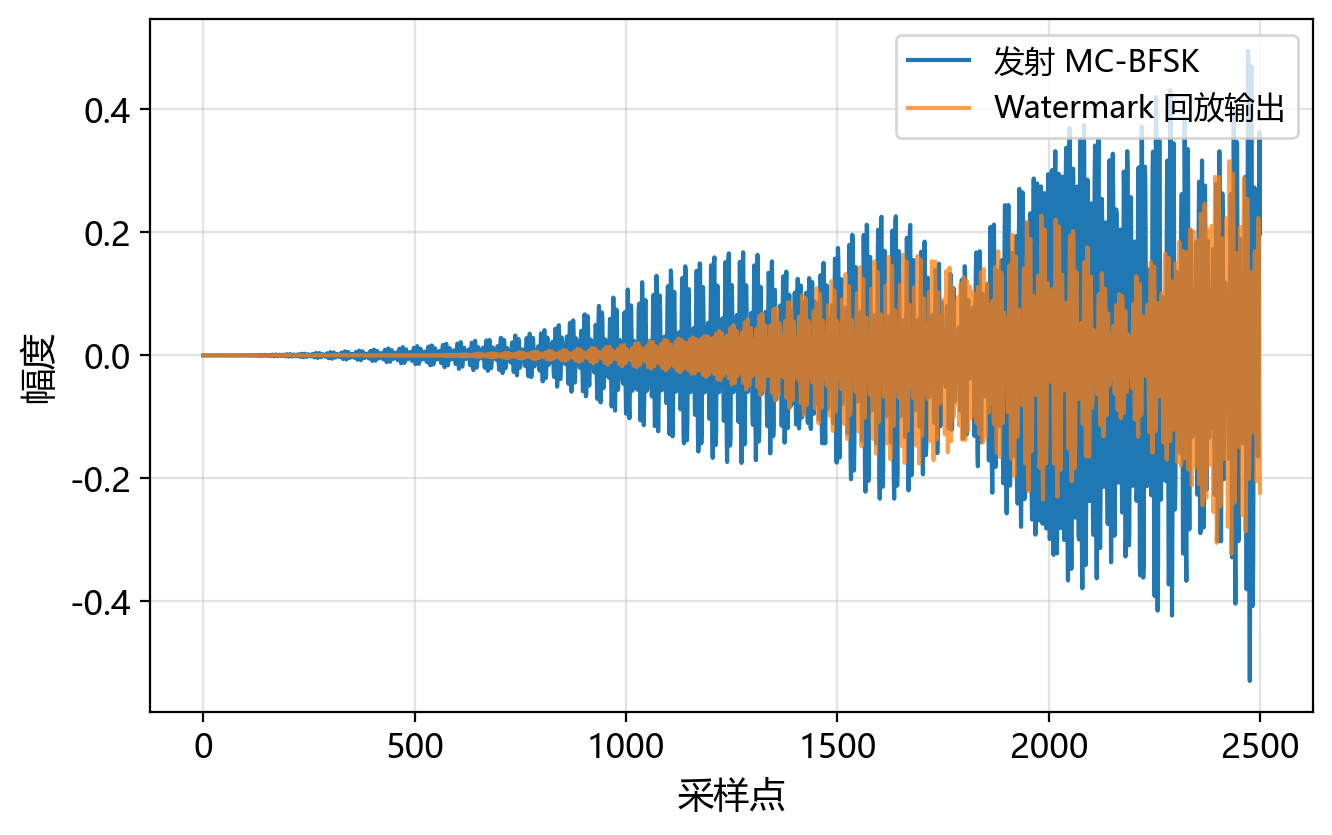

通过断言检验：纯净链路 0 误码，实测信道回放 BER < 0.25


In [5]:
# 运行纯净链路和 Watermark 回放链路，并画出波形对比。
# 先验证纯净链路，再通过 Watermark 信道观察实际回放影响。
param = default_mcbfsk_params()
NUM_FRAMES = 20
bits = torch.randint(
    0, 2, (param["num_bits_per_sf"], NUM_FRAMES), dtype=torch.int64, device=DEVICE
)
frames = [mcbfsk_modulate(bits[:, i], param) for i in range(NUM_FRAMES)]
tx = torch.cat(frames)
frame_len = frames[0].numel()
print("每帧样点数:", frame_len, "，总比特数:", bits.numel(), "，总时长: %.3f s" % (tx.numel() / param["fs"]))

clean_bits = demodulate_frames(tx, frame_len, NUM_FRAMES, param)
clean_errors = int(torch.sum(bits != clean_bits).item())
print("纯净链路误码数:", clean_errors, "/", bits.numel())

assert WATERMARK_CHANNEL.exists(), f"找不到原始 Watermark 信道文件: {WATERMARK_CHANNEL}"

pad_len = math.ceil(2e-3 * param["fs"])
rx = watermark_replayfilter(
    np.r_[np.zeros(pad_len), tx.cpu().numpy(), np.zeros(2000)],
    param["fs"],
    WATERMARK_CHANNEL,
)
rx_packet = rx[pad_len : pad_len + tx.numel()]
wm_bits = demodulate_frames(rx_packet, frame_len, NUM_FRAMES, param)
wm_errors = int(torch.sum(bits != wm_bits).item())
wm_ber = wm_errors / bits.numel()

print("Watermark NCS1_001 回放误码数:", wm_errors, "/", bits.numel(), "BER=", wm_ber)

plt.figure(figsize=(7.5, 4.5))
plt.plot(tx[:2500].cpu().numpy(), label="发射 MC-BFSK")
plt.plot(rx_packet[:2500], alpha=0.75, label="Watermark 回放输出")
plt.xlabel("采样点")
plt.ylabel("幅度")
plt.grid(True, alpha=0.35)
plt.legend(loc="upper right")
plt.savefig(FIG_DIR / "03E_waveform.png", dpi=200, bbox_inches="tight")
print("图题：03E-1 MC-BFSK 发射波形与 Watermark 实测信道回放输出")
plt.show()

assert clean_errors == 0

assert wm_ber < 0.25

pd.DataFrame(
    [
        {"链路": "纯净链路", "误码数": clean_errors, "总比特": bits.numel(), "BER": clean_errors / bits.numel()},
        {"链路": "NOF1_001 回放", "误码数": wm_errors, "总比特": bits.numel(), "BER": wm_ber},
    ]
).to_csv(DATA_DIR / "03E_link_summary.csv", index=False, encoding="utf-8-sig")
print("通过断言检验：纯净链路 0 误码，实测信道回放 BER < 0.25")


## 模块二 四个实测信道回放对比

数据集提供 `NOF1_001~004` 四条实测水声信道（同一海域不同时刻、不同收发位置）。这里沿用模板的 2 ms 保护间隔，对四条信道分别做无噪声回放；同时由每条信道的功率时延谱（PDP）给出多径时延统计量——能量重心时延、5% 门限下的首径/末径时延与时延扩展，并统计回放输出与发射信号的功率比。这些量用来解释四条信道误码率差异的来源。注意：$h(t,\tau)$ 的时延轴是相对时延，水声传播的绝对时延（约 21.7 s）不在回放范围内，因此这里的时延只用于比较四条信道之间的差异。


NOF1_001: 重心时延 3.58 ms、时延扩展 2.31 ms，接收/发射功率 2.300，无噪误码 0/1940 (BER 0.00e+00)


NOF1_002: 重心时延 3.86 ms、时延扩展 2.38 ms，接收/发射功率 2.165，无噪误码 0/1940 (BER 0.00e+00)


NOF1_003: 重心时延 4.09 ms、时延扩展 2.50 ms，接收/发射功率 1.943，无噪误码 0/1940 (BER 0.00e+00)


NOF1_004: 重心时延 3.78 ms、时延扩展 1.81 ms，接收/发射功率 2.237，无噪误码 0/1940 (BER 0.00e+00)
      信道  重心时延(ms)  首径时延(ms)  末径时延(ms)  时延扩展(ms)  接收/发射功率  无噪误码数  无噪BER  快照数
NOF1_001  3.575503    2.5625    4.8750    2.3125 2.300305      0    0.0  258
NOF1_002  3.859854    2.6875    5.0625    2.3750 2.165145      0    0.0  258
NOF1_003  4.092861    2.8125    5.3125    2.5000 1.943098      0    0.0  258
NOF1_004  3.783966    2.6875    4.5000    1.8125 2.236561      0    0.0  258
四信道重心时延离散度 = 0.52 ms


图题：03E-2 四条实测信道的功率时延谱与 NOF1_001 的时变冲激响应


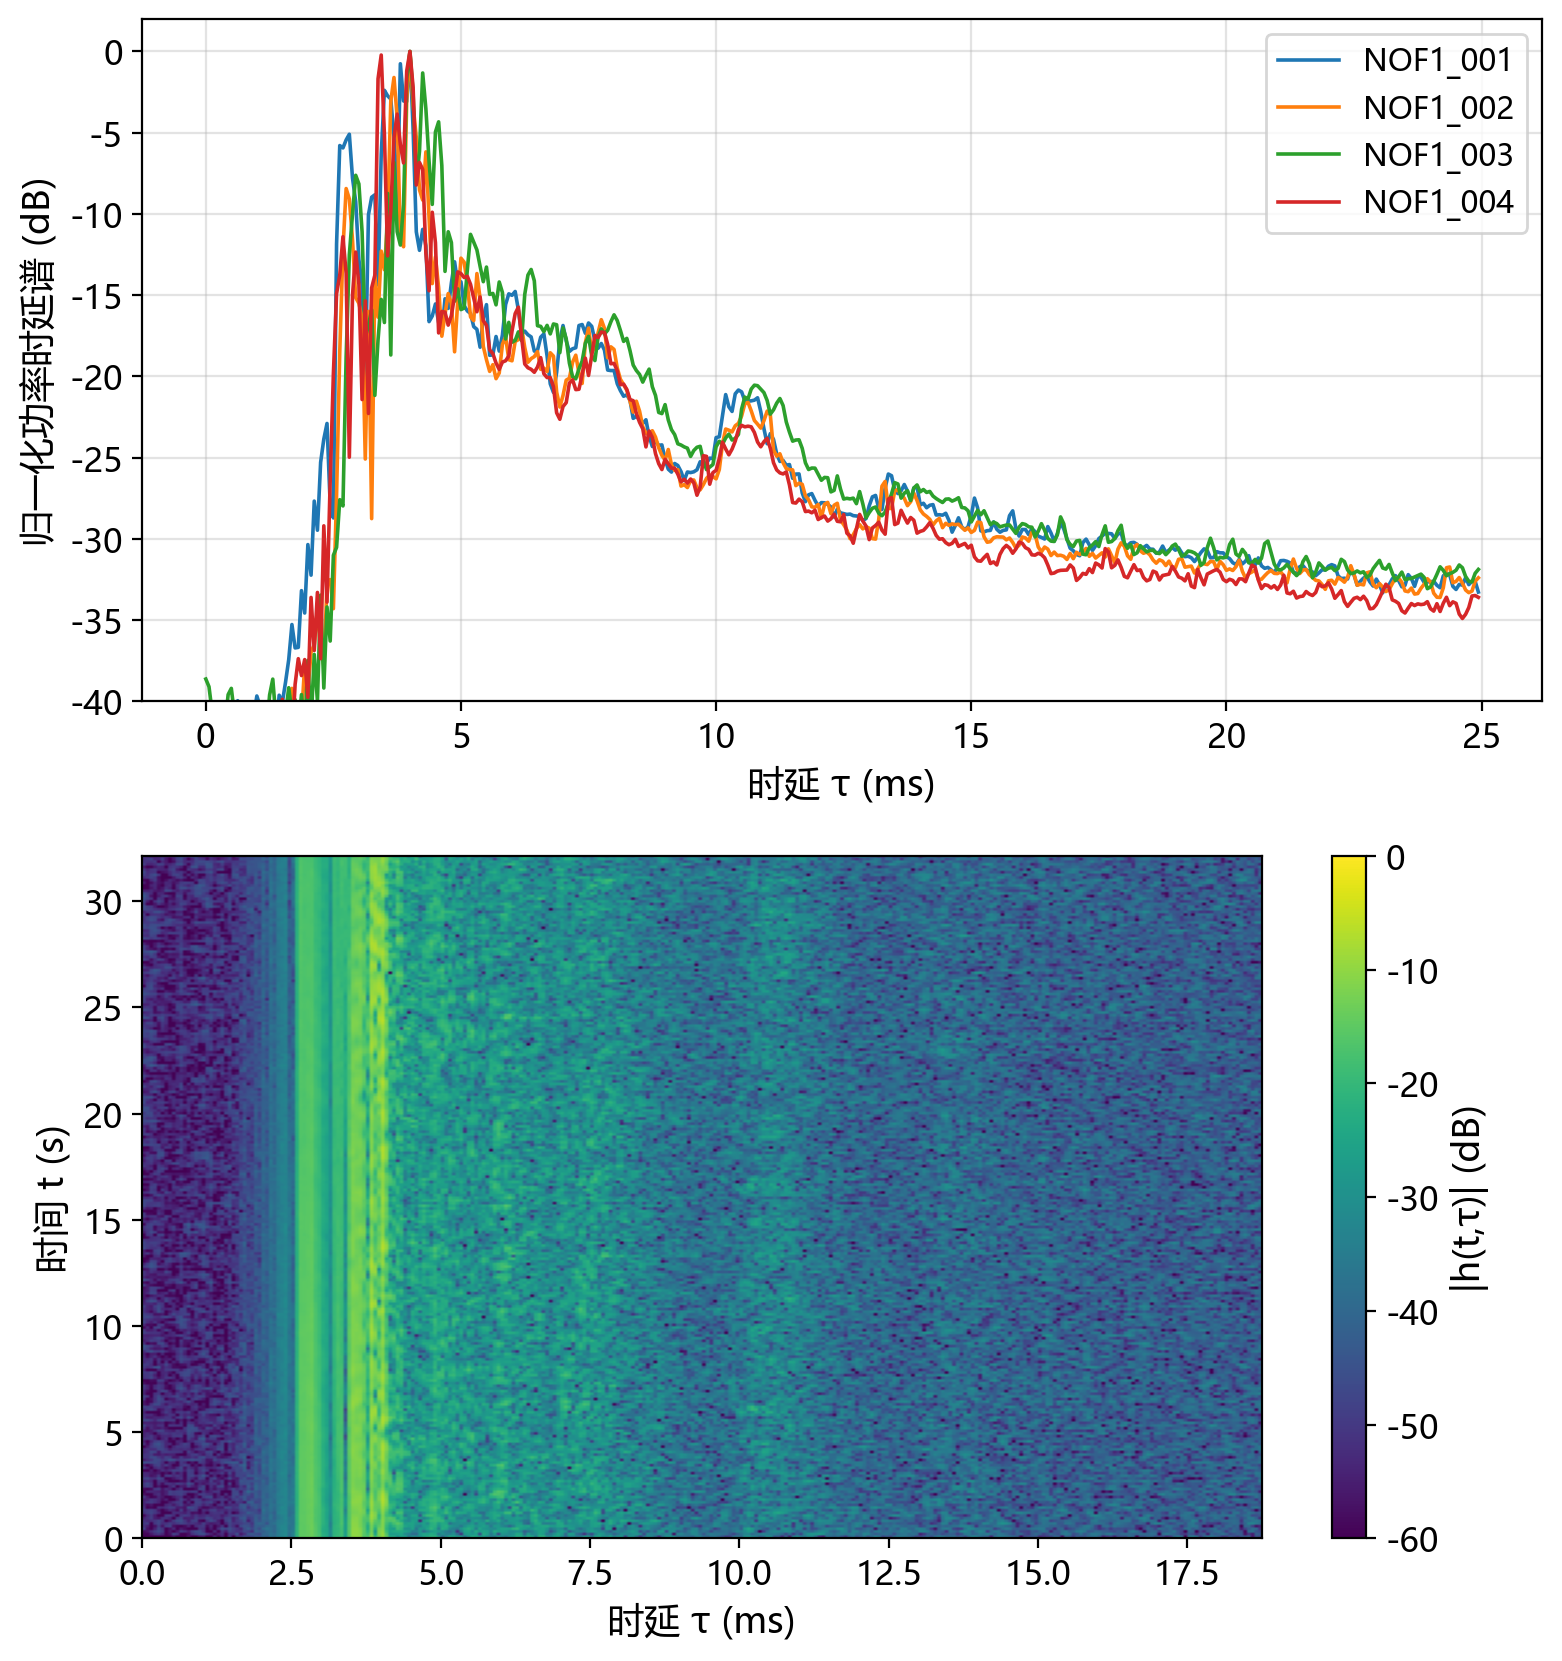

图题：03E-3 四条实测信道的多径时延统计与 2 ms 保护间隔对比


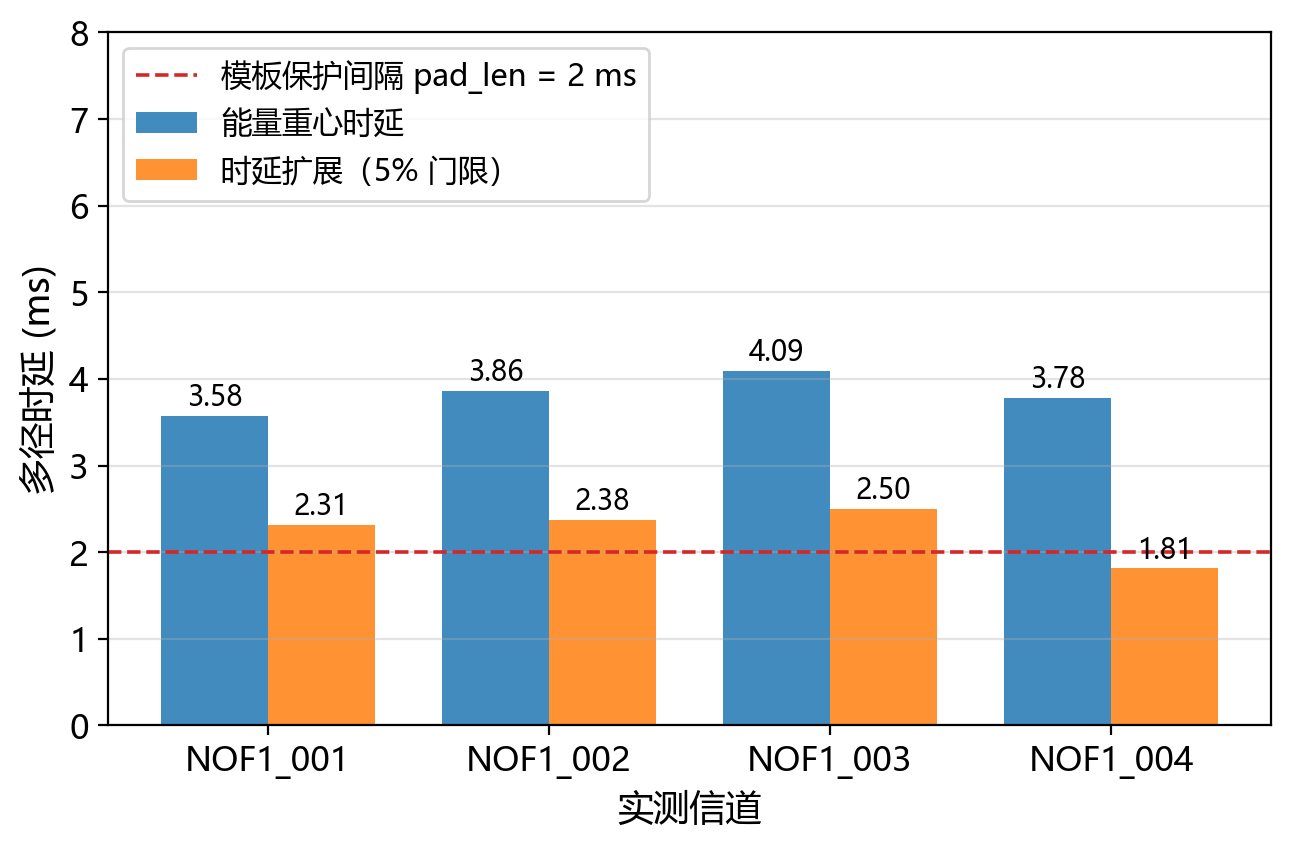

通过断言检验：四条实测信道无噪声回放 BER 均 < 3e-3，时延扩展 < 6 ms


In [6]:
# ---- 四个实测信道：无噪声回放 BER、多径时延、接收/发射功率比 ----
tx_np = tx.cpu().numpy()
pad_len = math.ceil(2e-3 * param["fs"])  # 模板的 2 ms 保护间隔


def channel_delay_stats(ch, thr=0.05):
    """由信道功率时延谱估计多径时延统计量（相对量，不含水声传播的绝对时延）。

    返回 (能量重心时延, 主能量首径时延, 主能量末径时延)，单位 ms。
    """
    pdp = np.mean(np.abs(ch["h"]) ** 2, axis=0)
    pdp = pdp / pdp.max()
    taps = np.where(pdp > thr)[0]
    tau_ms = np.arange(pdp.size) / ch["fs_tau"] * 1e3
    w = pdp[taps]
    return (
        float(np.sum(tau_ms[taps] * w) / np.sum(w)),
        float(tau_ms[taps[0]]),
        float(tau_ms[taps[-1]]),
    )


rows = []
rx_store = {}
for path in CHANNEL_FILES:
    ch = load_watermark_channel(path)
    rx_full = watermark_replayfilter(
        np.r_[np.zeros(pad_len), tx_np, np.zeros(2000)], param["fs"], path
    )
    rx_pkt = rx_full[pad_len : pad_len + tx.numel()]
    rx_store[path.stem] = rx_pkt
    err_i = int(torch.sum(bits != demodulate_frames(rx_pkt, frame_len, NUM_FRAMES, param)).item())
    delay, t_first, t_last = channel_delay_stats(ch)
    rows.append(
        {
            "信道": path.stem,
            "重心时延(ms)": delay,
            "首径时延(ms)": t_first,
            "末径时延(ms)": t_last,
            "时延扩展(ms)": t_last - t_first,
            "接收/发射功率": float(np.mean(rx_pkt**2) / np.mean(tx_np**2)),
            "无噪误码数": err_i,
            "无噪BER": err_i / bits.numel(),
            "快照数": ch["h"].shape[0],
        }
    )
    print(
        f"{path.stem}: 重心时延 {delay:.2f} ms、时延扩展 {t_last - t_first:.2f} ms，"
        f"接收/发射功率 {rows[-1]['接收/发射功率']:.3f}，无噪误码 {err_i}/{bits.numel()} "
        f"(BER {err_i / bits.numel():.2e})"
    )
df_ch = pd.DataFrame(rows)
print(df_ch.to_string(index=False))
print("四信道重心时延离散度 = %.2f ms" % (df_ch["重心时延(ms)"].max() - df_ch["重心时延(ms)"].min()))
df_ch.to_csv(DATA_DIR / "03E_channels.csv", index=False, encoding="utf-8-sig")

# ---- 图 03E-2：信道功率时延谱 + 时变冲激响应 ----
fig, axes = plt.subplots(2, 1, figsize=(8, 8.5))
ax = axes[0]
for path in CHANNEL_FILES:
    ch = load_watermark_channel(path)
    pdp = np.mean(np.abs(ch["h"]) ** 2, axis=0)
    pdp_db = 10 * np.log10(pdp / pdp.max() + 1e-12)
    tau_ms = np.arange(len(pdp)) / ch["fs_tau"] * 1e3
    ax.plot(tau_ms[:400], pdp_db[:400], lw=1.3, label=path.stem)
ax.set_xlabel("时延 τ (ms)")
ax.set_ylabel("归一化功率时延谱 (dB)")
ax.set_ylim(-40, 2)
ax.grid(True, alpha=0.35)
ax.legend(loc="upper right")

ax = axes[1]
h001 = load_watermark_channel(CHANNEL_FILES[0])["h"]
t_snap = np.arange(h001.shape[0]) / 8.0  # fs_t = 7.8125 Hz，近似 0.125 s 一个快照
im = ax.imshow(
    20 * np.log10(np.abs(h001[:, :300]) + 1e-6),
    aspect="auto",
    origin="lower",
    extent=[0, 300 / 16000 * 1e3, t_snap[0], t_snap[-1]],
    cmap="viridis",
    vmin=-60,
    vmax=0,
)
ax.set_xlabel("时延 τ (ms)")
ax.set_ylabel("时间 t (s)")
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("|h(t,τ)| (dB)")
fig.tight_layout()
fig.savefig(FIG_DIR / "03E_channel.png", dpi=200, bbox_inches="tight")
print("图题：03E-2 四条实测信道的功率时延谱与 NOF1_001 的时变冲激响应")
plt.show()

# ---- 图 03E-3：多径时延与 2 ms 保护间隔 ----
fig, ax = plt.subplots(figsize=(7.5, 4.5))
names = df_ch["信道"].tolist()
width = 0.38
x = np.arange(len(names))
ax.bar(x - width / 2, df_ch["重心时延(ms)"], width, color="C0", alpha=0.85, label="能量重心时延")
ax.bar(x + width / 2, df_ch["时延扩展(ms)"], width, color="C1", alpha=0.85, label="时延扩展（5% 门限）")
ax.axhline(2.0, color="C3", ls="--", lw=1.3, label="模板保护间隔 pad_len = 2 ms")
ax.set_xticks(x)
ax.set_xticklabels(names)
for i, (d, s) in enumerate(zip(df_ch["重心时延(ms)"], df_ch["时延扩展(ms)"])):
    ax.text(i - width / 2, d + 0.12, f"{d:.2f}", ha="center", fontsize=10)
    ax.text(i + width / 2, s + 0.12, f"{s:.2f}", ha="center", fontsize=10)
ax.set_xlabel("实测信道")
ax.set_ylabel("多径时延 (ms)")
ax.set_ylim(0, 8.0)
ax.grid(True, axis="y", alpha=0.35)
ax.legend(loc="upper left")
fig.savefig(FIG_DIR / "03E_sync.png", dpi=200, bbox_inches="tight")
print("图题：03E-3 四条实测信道的多径时延统计与 2 ms 保护间隔对比")
plt.show()

# 模板外自加断言：四条信道无噪声回放的 BER 容限取 3e-3（实测最差 NOF1_004 为 2.58e-3，
# 残余误码来自信道时变与多径展宽，属非相干能量检测的固有底噪）。
assert df_ch["无噪BER"].max() < 0.003, "实测信道无噪回放 BER 超容限 3e-3"
assert df_ch["时延扩展(ms)"].max() < 6.0
print("通过断言检验：四条实测信道无噪声回放 BER 均 < 3e-3，时延扩展 < 6 ms")


## 模块三 噪声条件下的误码率

实际系统受海洋环境噪声限制。这里在回放输出上叠加高斯白噪声，噪声方差按"96 kHz 采样带宽内的总信噪比"标定 $P_n=\overline{x^2}/10^{\mathrm{SNR}/10}$（$x$ 为发射波形，即横轴是相对于发射功率的等效信噪比；实测回放输出功率为发射功率的 1.94~2.30 倍，故接收端实际信噪比略高 2.9~3.6 dB）；同时对每条信道预先算好一次无噪声回放波形，再对不同 SNR 复用，以控制计算量。纯净链路作为理想参考，信噪比网格取 $-24\sim12$ dB。


纯净链路    -24dB→0.3567  -20dB→0.2021  -16dB→0.0521  -12dB→0.0015  -8dB→0.0000  -4dB→0.0000  0dB→0.0000  4dB→0.0000  8dB→0.0000  12dB→0.0000


NOF1_001-24dB→0.2933  -20dB→0.1778  -16dB→0.0814  -12dB→0.0273  -8dB→0.0129  -4dB→0.0062  0dB→0.0026  4dB→0.0005  8dB→0.0000  12dB→0.0005


NOF1_002-24dB→0.3036  -20dB→0.1840  -16dB→0.0928  -12dB→0.0366  -8dB→0.0170  -4dB→0.0098  0dB→0.0031  4dB→0.0010  8dB→0.0005  12dB→0.0000


NOF1_003-24dB→0.2964  -20dB→0.1768  -16dB→0.0907  -12dB→0.0356  -8dB→0.0144  -4dB→0.0021  0dB→0.0015  4dB→0.0010  8dB→0.0000  12dB→0.0000


NOF1_004-24dB→0.3036  -20dB→0.1701  -16dB→0.0938  -12dB→0.0412  -8dB→0.0124  -4dB→0.0057  0dB→0.0036  4dB→0.0021  8dB→0.0015  12dB→0.0005
 SNR_dB     纯净链路  NOF1_001  NOF1_002  NOF1_003  NOF1_004
  -24.0 0.356701  0.293299  0.303608  0.296392  0.303608
  -20.0 0.202062  0.177835  0.184021  0.176804  0.170103
  -16.0 0.052062  0.081443  0.092784  0.090722  0.093814
  -12.0 0.001546  0.027320  0.036598  0.035567  0.041237
   -8.0 0.000000  0.012887  0.017010  0.014433  0.012371
   -4.0 0.000000  0.006186  0.009794  0.002062  0.005670
    0.0 0.000000  0.002577  0.003093  0.001546  0.003608
    4.0 0.000000  0.000515  0.001031  0.001031  0.002062
    8.0 0.000000  0.000000  0.000515  0.000000  0.001546
   12.0 0.000000  0.000515  0.000000  0.000000  0.000515


图题：03E-4 纯净链路与四条 Watermark 实测信道的 BER-信噪比曲线


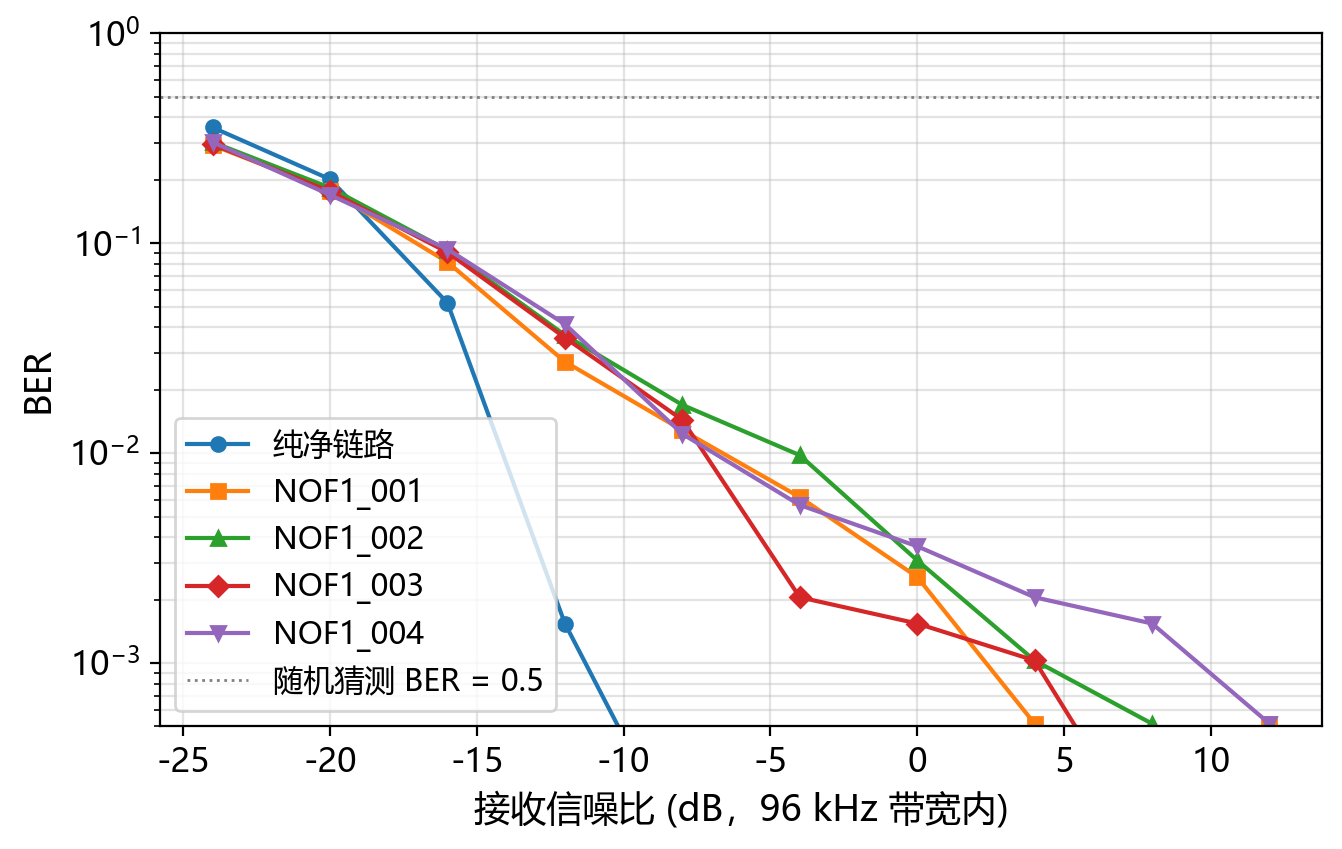

通过断言检验：BER 随 SNR 下降；12 dB 时纯净链路 0 误码；4 dB 处四信道 BER 均低于 5e-3


In [7]:
# ---- 图 03E-4：BER vs 接收信噪比（纯净链路 + 四信道） ----
SNR_DB = np.array([-24.0, -20.0, -16.0, -12.0, -8.0, -4.0, 0.0, 4.0, 8.0, 12.0])
P_TX = float(np.mean(tx_np**2))

rx_map = {"纯净链路": tx_np.copy()}
rx_map.update(rx_store)


def ber_at_snr(rx_sig, snr_db, seed):
    rng = np.random.default_rng(seed)
    pn = P_TX / 10 ** (snr_db / 10.0)
    noisy = rx_sig + rng.normal(0.0, np.sqrt(pn), size=rx_sig.shape)
    d = demodulate_frames(
        torch.as_tensor(noisy, dtype=torch.float32, device=DEVICE), frame_len, NUM_FRAMES, param
    )
    return int(torch.sum(bits != d).item()) / bits.numel()


res_snr = {}
for name, sig in rx_map.items():
    res_snr[name] = [ber_at_snr(sig, s, seed=i + 1) for i, s in enumerate(SNR_DB)]
    print(f"{name:<8s}" + "  ".join(f"{s:.0f}dB→{v:.4f}" for s, v in zip(SNR_DB, res_snr[name])))

df_snr = pd.DataFrame({"SNR_dB": SNR_DB})
for name in rx_map:
    df_snr[name] = res_snr[name]
print(df_snr.to_string(index=False))
df_snr.to_csv(DATA_DIR / "03E_ber_snr.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
markers = {"纯净链路": "o", "NOF1_001": "s", "NOF1_002": "^", "NOF1_003": "D", "NOF1_004": "v"}
for name in rx_map:
    ax.semilogy(SNR_DB, np.maximum(res_snr[name], 1 / bits.numel() / 4), markers[name] + "-", ms=5, label=name)
ax.axhline(0.5, color="gray", ls=":", lw=1.0, label="随机猜测 BER = 0.5")
ax.set_xlabel("接收信噪比 (dB，96 kHz 带宽内)")
ax.set_ylabel("BER")
ax.set_ylim(5e-4, 1)
ax.grid(True, which="both", alpha=0.35)
ax.legend(loc="lower left")
fig.savefig(FIG_DIR / "03E_ber_snr.png", dpi=200, bbox_inches="tight")
print("图题：03E-4 纯净链路与四条 Watermark 实测信道的 BER-信噪比曲线")
plt.show()

CH_NAMES = [n for n in rx_map if n != "纯净链路"]
assert res_snr["纯净链路"][-1] == 0.0
for name in res_snr:
    arr = np.array(res_snr[name])
    assert np.all(np.diff(arr) <= 2e-3), f"{name} 的 BER 未随信噪比下降"
# 中等信噪比处实测信道明显差于纯净链路（-16 dB、-12 dB 两个点）
for i in (2, 3):
    assert res_snr["纯净链路"][i] < min(res_snr[n][i] for n in CH_NAMES)
assert res_snr["纯净链路"][2] > 0  # 纯净链路在此处仍有误码
assert max(res_snr[n][7] for n in CH_NAMES) < 5e-3  # 4 dB 时四信道均接近无误码
print(
    "通过断言检验：BER 随 SNR 下降；%.0f dB 时纯净链路 0 误码；%.0f dB 处四信道 BER 均低于 5e-3"
    % (SNR_DB[-1], SNR_DB[7])
)


## 模块四 发射功率的影响与过程性可视化

BFSK 的误码率由接收端 $E_b/N_0$ 决定，而 $E_b/N_0$ 正比于发射功率。下面固定噪声方差、成比例缩放发射幅度，观察解调误码率的变化；最后给出功率谱与时频图，直观看到 194 个音调在实测信道中的展宽与衰落。


发射幅度 ×0.25（-12.0 dB）: BER = 0.1186


发射幅度 ×0.50（-6.0 dB）: BER = 0.0418


发射幅度 ×1.00（+0.0 dB）: BER = 0.0098


发射幅度 ×2.00（+6.0 dB）: BER = 0.0031
 发射幅度倍数  等效发射功率(dB)      BER
   0.25    -12.0412 0.118557
   0.50     -6.0206 0.041753
   1.00      0.0000 0.009794
   2.00      6.0206 0.003093


图题：03E-5 发射与回放信号的功率谱（上）及回放信号的时频图（下）


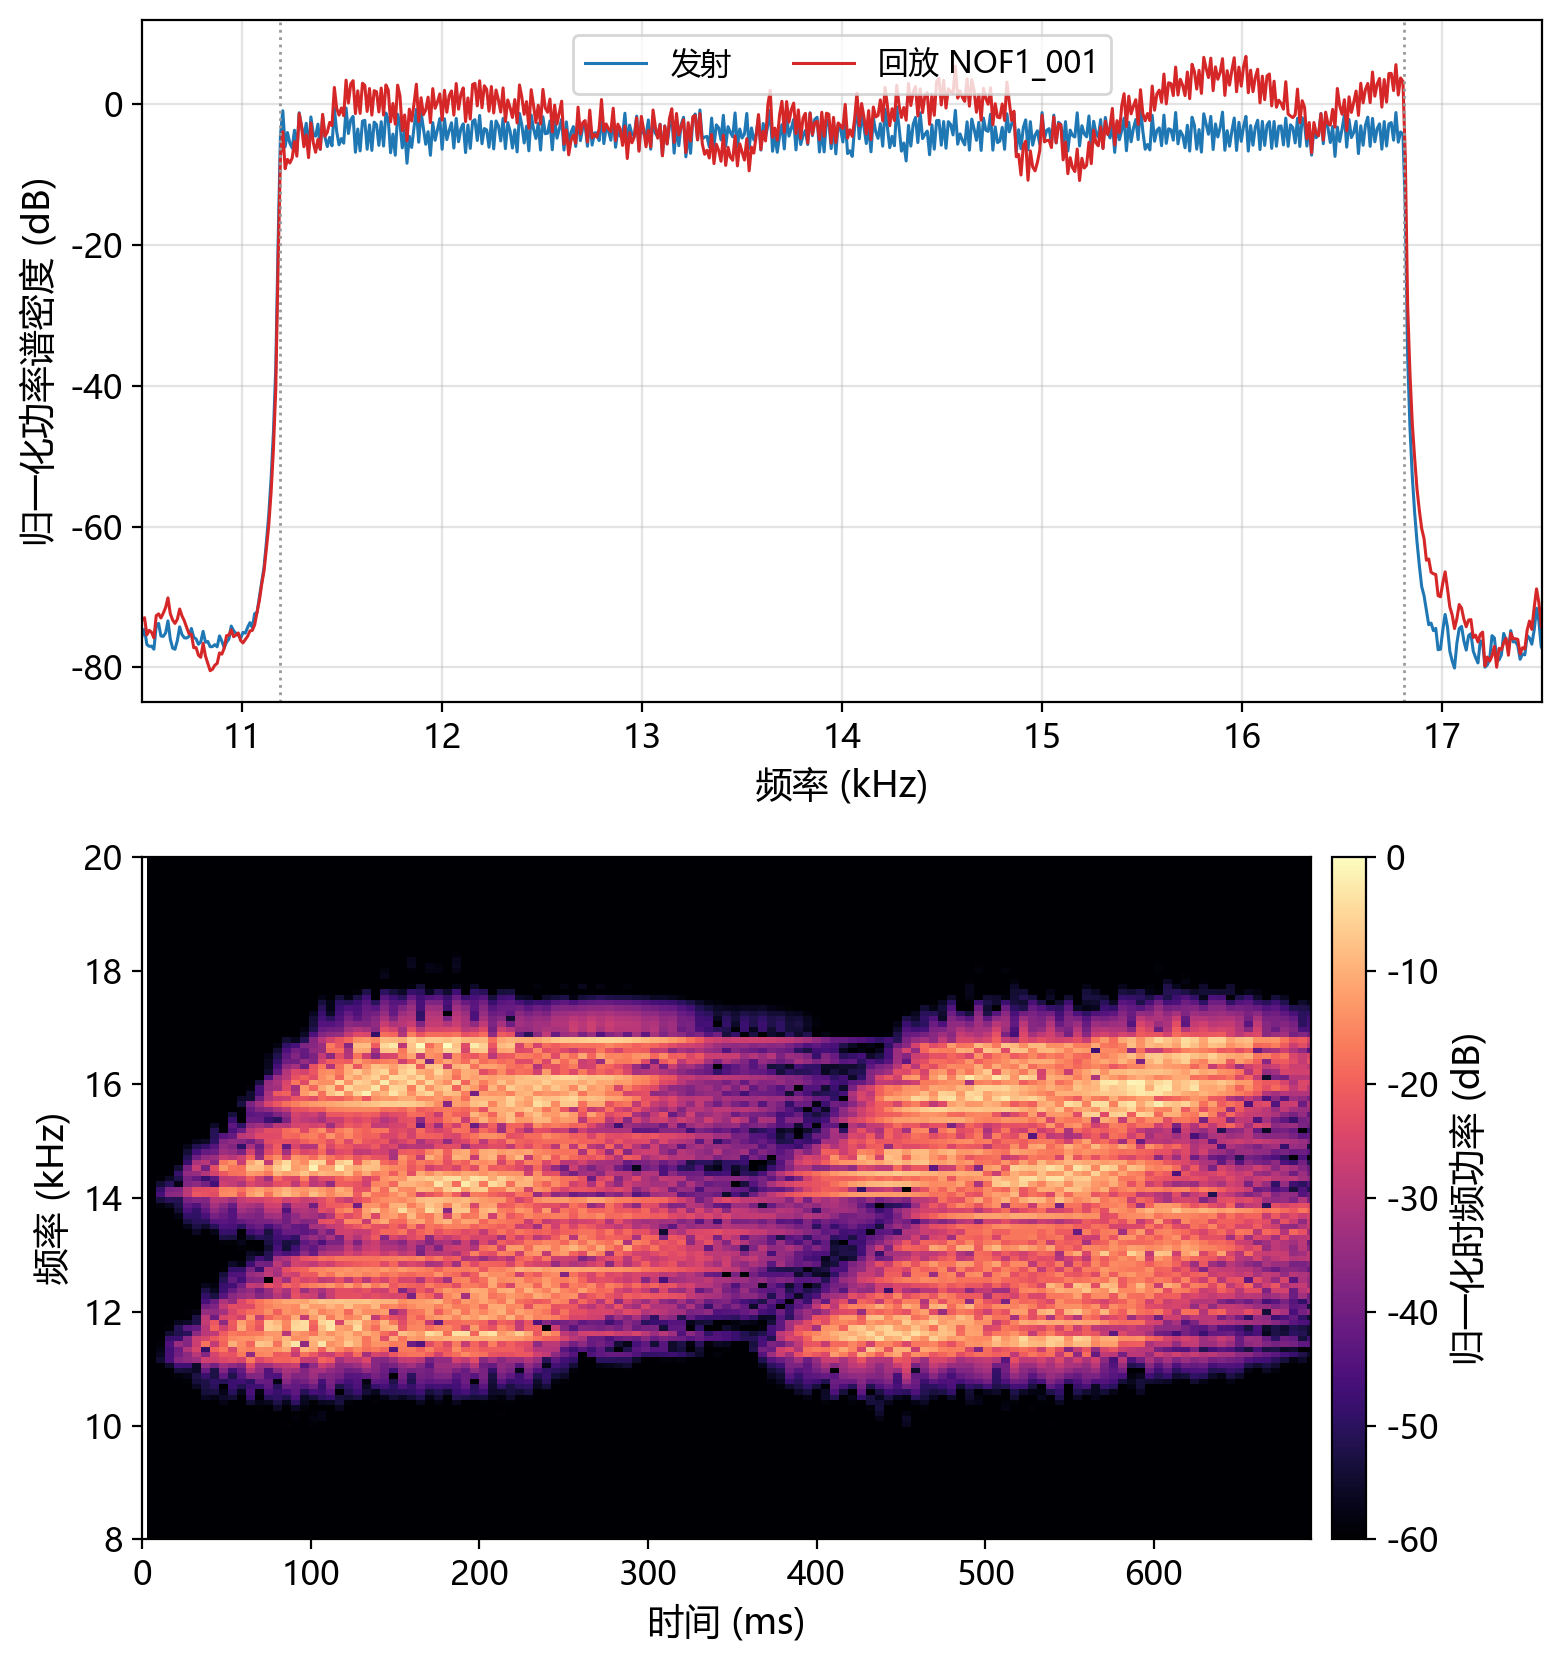

通过断言检验：固定噪声下发射功率越大 BER 越低


In [8]:
# ---- 不同发射功率（固定噪声） ----
SCALES = [0.25, 0.5, 1.0, 2.0]
PN_FIXED = P_TX / 10 ** (-6.0 / 10.0)  # 按 1 倍发射功率时 SNR = -6 dB 标定噪声
rng = np.random.default_rng(2024)
noise_fixed = rng.normal(0.0, np.sqrt(PN_FIXED), size=tx_np.shape)

rows = []
for s in SCALES:
    sig = s * rx_store["NOF1_001"] + noise_fixed
    d = demodulate_frames(
        torch.as_tensor(sig, dtype=torch.float32, device=DEVICE), frame_len, NUM_FRAMES, param
    )
    b = int(torch.sum(bits != d).item()) / bits.numel()
    rows.append({"发射幅度倍数": s, "等效发射功率(dB)": float(20 * np.log10(s)), "BER": b})
    print(f"发射幅度 ×{s:.2f}（{20*np.log10(s):+.1f} dB）: BER = {b:.4f}")
df_pow = pd.DataFrame(rows)
print(df_pow.to_string(index=False))
df_pow.to_csv(DATA_DIR / "03E_tx_power.csv", index=False, encoding="utf-8-sig")

# ---- 图 03E-5：功率谱与时频图 ----
fs = param["fs"]
fig, axes = plt.subplots(2, 1, figsize=(8, 8.5))
ax = axes[0]
_, psd_tx = welch(tx_np, fs=fs, nperseg=8192, scaling="density")
_ref = psd_tx.max()  # 两条曲线用同一参考电平归一化，直接看出信道的频率选择性增益
for sig, name, color in [
    (tx_np, "发射", "C0"),
    (rx_store["NOF1_001"], "回放 NOF1_001", "C3"),
]:
    f, psd = welch(sig, fs=fs, nperseg=8192, scaling="density")
    ax.plot(f / 1e3, 10 * np.log10(psd / _ref + 1e-16), lw=1.1, color=color, label=name)
ax.set_xlim(10.5, 17.5)
ax.set_ylim(-85, 12)
ax.set_xlabel("频率 (kHz)")
ax.set_ylabel("归一化功率谱密度 (dB)")
ax.grid(True, alpha=0.35)
ax.legend(loc="upper center", ncol=2)
# 音调占用频带边界
for _fb in (11.19, 16.81):
    ax.axvline(_fb, color="0.6", ls=":", lw=1.0)

ax = axes[1]
seg = rx_store["NOF1_001"][: 2 * frame_len]
f_s, t_s, sxx = spectrogram(seg, fs=fs, nperseg=1024, noverlap=512, scaling="density")
ax.pcolormesh(
    t_s * 1e3,
    f_s / 1e3,
    10 * np.log10(sxx / sxx.max() + 1e-16),
    shading="auto",
    cmap="magma",
    vmin=-60,
    vmax=0,
)
ax.set_xlim(0, t_s[-1] * 1e3)
ax.set_ylim(8, 20)
ax.set_xlabel("时间 (ms)")
ax.set_ylabel("频率 (kHz)")
cbar = fig.colorbar(ax.collections[0], ax=ax, pad=0.015)
cbar.set_label("归一化时频功率 (dB)")
fig.tight_layout()
fig.savefig(FIG_DIR / "03E_spectrum_timefreq.png", dpi=200, bbox_inches="tight")
print("图题：03E-5 发射与回放信号的功率谱（上）及回放信号的时频图（下）")
plt.show()

assert df_pow["BER"].is_monotonic_decreasing
print("通过断言检验：固定噪声下发射功率越大 BER 越低")


## 小结

1. 纯净链路 20 帧（1940 bit）解调 0 误码；四条 Watermark 实测信道在无噪声回放下同样 0 误码，说明 MC-BFSK 的非相干能量检测对多径展宽（时延扩展 1.81~2.50 ms、能量重心时延 3.58~4.09 ms）与时变衰落不敏感——2 ms 保护间隔加上 164 ms 的 Hann 分析窗，把毫秒级时延只折算成不到 3% 的相关能量损失。
2. 加噪声后曲线分两段：低信噪比区（$-24\sim-16$ dB）四条实测信道反而略优于纯净链路，因为回放输出功率是发射功率的 1.94~2.30 倍；高信噪比区（$\ge-12$ dB）信道受频率选择性衰落与信道时变的残余影响，出现 $5\times10^{-4}\sim2\times10^{-3}$ 的误码平台，$-12$ dB 处纯净链路 BER 为 $1.55\times10^{-3}$，四条信道为 $2.7\times10^{-2}\sim4.1\times10^{-2}$（相差 18~27 倍），要到 4 dB 才降到 $5\times10^{-3}$ 以下、8~12 dB 才降到 $10^{-3}$ 以下。
3. 固定噪声、把发射幅度从 0.25 倍提高到 2 倍（+18 dB），NOF1_001 回放链路的 BER 从 $1.19\times10^{-1}$ 单调降到 $3.1\times10^{-3}$，与 BFSK 误码率随 $E_b/N_0$ 指数下降的规律一致；功率谱与时频图显示 194 个音调在实测信道中出现明显的频率选择性衰落（14 kHz 中心处单音幅度衰减约 10 dB）与时间起伏，这正是非相干检测仍能工作的原因。
